# Oscillations and waves 6: Light as a wave

*Learning path: oscillations and waves, part 6 of 7.* [Index](README.md) · Previous: [Dispersion](05-dispersion.ipynb) · Next: [Geometric optics](07-geometric-optics.ipynb)

In 1801 Thomas Young let sunlight through a pinhole, then through two narrow slits close together, onto a screen.
Light from one slit lit the screen evenly; light from both made **dark stripes**, places where adding light gave
darkness. Particles can't do that. Waves can: where a crest from one slit meets a trough from the other, they cancel.
From the spacing of the stripes Young measured the wavelength of light, about half a micrometre. This lesson computes
interference and diffraction patterns, from two slits to a grating, and the finest detail a telescope can see.

**Who this is for.** You have done [lesson 5](05-dispersion.ipynb) and know complex numbers or at least sines and
cosines of sums.

**What you will be able to do afterwards:**

1. relate wavelength, frequency and colour, and compute path differences;
2. compute the double-slit pattern and its fringe spacing;
3. compute single-slit diffraction by adding many small waves (Huygens' principle);
4. explain gratings, the colours of a CD, and the resolution limit of a telescope.

Plan about an hour and a half.

## 1. Light, wavelength and colour

Visible light has wavelengths from about 400 nm (violet) to 700 nm (red), and travels at $c$, so its frequency is
$f = c/\lambda$. For green light at 550 nm:

In [1]:
eval(convert(const.c/(550 nm), Hz), 3)

5.45e14 Hz

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

Over 500 trillion oscillations per second, far too fast for any detector to follow. What we can see is the
**intensity**, the time average of the square of the wave. Two waves of equal amplitude meeting with a phase difference
$\phi$ add up to an intensity proportional to $|1 + e^{i\phi}|^2 = 2 + 2\cos\phi$: four times one wave's intensity
when they are in step ($\phi = 0$), zero when they are opposite ($\phi = \pi$). A path difference $\Delta$ gives
$\phi = 2\pi\Delta/\lambda$.

**Try this.** How many wavelengths of red light (650 nm) fit in a millimetre?

## 2. The double slit

Two slits a distance $d$ apart send light to a screen at angle $\theta$. The path from the far slit is longer by
$d\sin\theta$, so bright fringes sit where $d\sin\theta = m\lambda$, and the intensity is
$\cos^2(\pi d\sin\theta/\lambda)$. On a screen at distance $L$, the bright fringes are $\lambda L/d$ apart. For green
light, slits 0.2 mm apart and a screen 1 m away:

In [2]:
eval(convert(550 nm*1 m/(0.2 mm), mm), 3)

2.75 mm

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

2.75 mm, easy to see. Young measured the spacing and worked backwards to the wavelength.

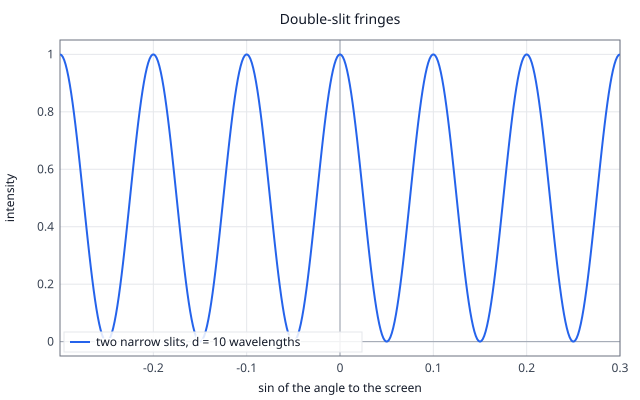

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [3]:
p = plot(cos(pi*10*s)^2, s, -0.3, 0.3);
p = legend(p, "two narrow slits, d = 10 wavelengths");
labels(title(p, "Double-slit fringes"), "sin of the angle to the screen", "intensity")

**Try this.** Red light (650 nm) through the same slits: are the fringes closer or farther apart?

## 3. Diffraction by one slit

A real slit has a width $a$. **Huygens' principle**: treat every point of the opening as a source of small waves, and
add them up. Take 40 sources spread over a slit 5 wavelengths wide. At angle $\theta$ the source at position $y$ is
ahead by the phase $2\pi y\sin\theta/\lambda$; add the cosines and the sines separately and square:

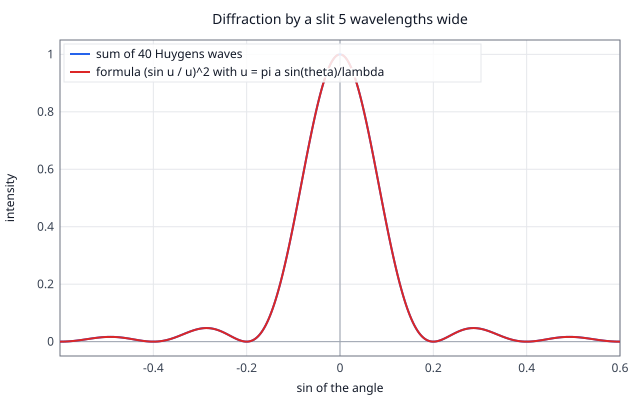

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [4]:
C = 0; S = 0;
for j in 1:40
  y = 5*(j - 20.5)/40;
  C = C + cos(2*pi*y*s);
  S = S + sin(2*pi*y*s);
end
I = (C^2 + S^2)/1600;
p = plot(I, s, -0.6, 0.6);
p = show(p, plot((sin(5*pi*s)/(5*pi*s))^2, s, -0.6, 0.6));
p = legend(p, "sum of 40 Huygens waves", "formula (sin u / u)^2 with u = pi a sin(theta)/lambda");
labels(title(p, "Diffraction by a slit 5 wavelengths wide"), "sin of the angle", "intensity")

The sum of 40 waves and the formula $\left(\frac{\sin u}{u}\right)^2$ (from an integral instead of a sum) lie on top of
each other. The central bright band reaches out to $\sin\theta = \lambda/a$, where the waves from the two halves of
the slit cancel in pairs. A narrower slit spreads the light **more**: squeeze a beam and it fans out. That is why a
laser beam can't be kept thin over long distances.

**Real double slits** have width too: the pattern is the double-slit fringes times the single-slit envelope. Slits 2
wavelengths wide, 10 wavelengths apart:

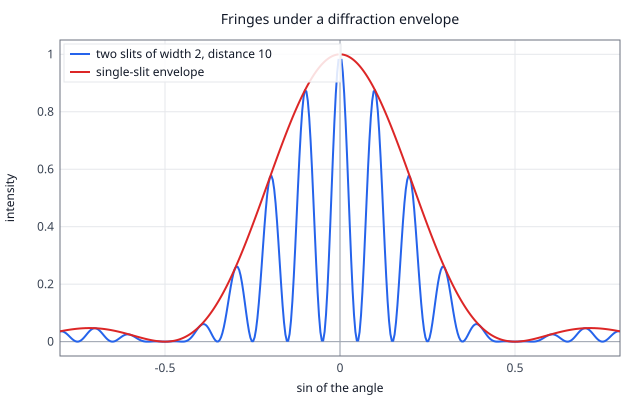

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [5]:
p = plot(cos(pi*10*s)^2*(sin(2*pi*s)/(2*pi*s))^2, s, -0.8, 0.8);
p = show(p, plot((sin(2*pi*s)/(2*pi*s))^2, s, -0.8, 0.8));
p = legend(p, "two slits of width 2, distance 10", "single-slit envelope");
labels(title(p, "Fringes under a diffraction envelope"), "sin of the angle", "intensity")

**Try this.** Fringes missing from the pattern sit where a bright fringe falls on a zero of the envelope. Which
fringe orders $m$ are missing for $d = 10$, $a = 2$?

## 4. Gratings and resolution

Many slits, $N$ of them, $d$ apart, give the intensity
$\left(\frac{\sin(N\pi d\sin\theta/\lambda)}{\sin(\pi d\sin\theta/\lambda)}\right)^2$: bright fringes at the same
angles as for two slits, but $N$ times narrower. With $d = 4$ wavelengths:

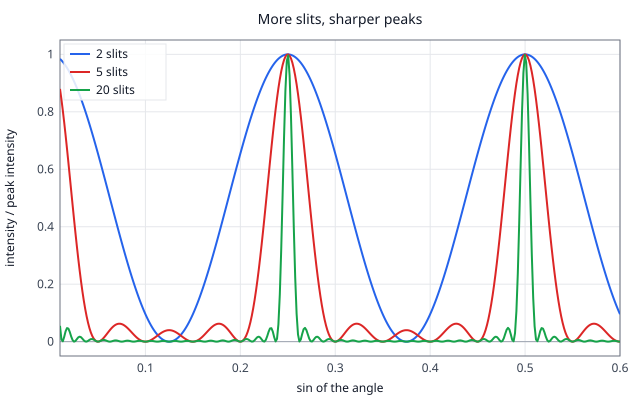

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [6]:
G(N) := (sin(N*pi*4*s)/sin(pi*4*s))^2/N^2;
p = plot(G(2), s, 0.01, 0.6);
p = show(p, plot(G(5), s, 0.01, 0.6));
p = show(p, plot(G(20), s, 0.01, 0.6));
p = legend(p, "2 slits", "5 slits", "20 slits");
labels(title(p, "More slits, sharper peaks"), "sin of the angle", "intensity / peak intensity")

Sharp peaks at angles that depend on the wavelength make a **grating** a precise way to split light into colours. A
CD is one: its track spacing is 1.6 μm, so red light (650 nm) comes off in first order at

In [7]:
eval(asin(650 nm/(1.6 um))*180/pi, 3)

24.0

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

degrees, and violet at a smaller angle: the rainbow on the back of a disc.

**Resolution.** A telescope's round mirror of diameter $D$ is an opening too, and spreads the light of a point star
into a small disc of angular radius $1.22\lambda/D$. Two stars closer than that blur into one (the **Rayleigh
criterion**). For the Hubble Space Telescope (2.4 m) in green light, in arcseconds:

In [8]:
eval(1.22*550 nm/(2.4 m)*180/pi*3600, 3)

0.0577

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

0.058 arcseconds, about the size of a coin seen from 80 km. Bigger mirrors see finer detail, which is one reason
telescopes keep growing.

**Try this.** Your pupil is about 3 mm wide. What is the finest angle your eye can resolve, in arcminutes?

## Summary

* Light is a wave of 400 to 700 nm; intensities add as $|{\rm sum\ of\ waves}|^2$, so waves can cancel.
* Double slit: bright fringes at $d\sin\theta = m\lambda$, spaced $\lambda L/d$ on a screen.
* A slit of width $a$ diffracts light into $(\sin u/u)^2$ with $u = \pi a\sin\theta/\lambda$: narrower slits spread
  light more.
* $N$ slits make peaks $N$ times sharper (gratings); a round opening limits resolution to $1.22\lambda/D$.

Next: [geometric optics](07-geometric-optics.ipynb), the limit where wavelengths are too small to matter.

## Exercises

1. **Soap film.** Light reflected from the two faces of a soap film 300 nm thick (refractive index 1.33) interferes.
   The path difference is $2nt$, plus a half wavelength from the reflection at the front face. Which visible
   wavelength is strongest?
2. **Thin slit.** For a slit 1 wavelength wide, where is the first zero of the pattern? What happens for a slit
   narrower than a wavelength?
3. **Grating spectrometer.** A grating with 600 lines per millimetre: at what angles do the sodium lines at 589.0 and
   589.6 nm appear in first order? How many lines must be lit to resolve them ($\lambda/\Delta\lambda < N$)?
4. **Electrons.** Electrons also show double-slit fringes, with $\lambda = h/p$. What is the wavelength of an electron
   moving at $10^6$ m/s (`const.h`, `const.me`)?
5. **Radio telescopes.** A radio dish 100 m across observes at 21 cm. Compare its resolution with Hubble's.
6. **Sum of phasors.** Show that the sum $\sum_{j=0}^{N-1}e^{ij\phi}$ has size $|\sin(N\phi/2)/\sin(\phi/2)|$, the
   grating formula. (It is a geometric series.)

## Hints and answers

* **Section 1, Try this.** $1/(650\cdot10^{-9}) \approx 1540$.
* **Section 2, Try this.** Farther apart: 3.25 mm.
* **Section 3, Try this.** Bright fringes at $\sin\theta = m/10$, envelope zeros at $\sin\theta = k/2$: orders
  $m = 5, 10, 15, \ldots$ are missing.
* **Section 4, Try this.** $1.22 \cdot 550\cdot10^{-9}/0.003$ rad $\approx 0.77$ arcminutes, close to the eye's
  measured acuity of about 1 arcminute.
* **Exercise 1.** Bright when $2nt = (m + \tfrac12)\lambda$: $798/(m + \tfrac12)$ nm gives 532 nm (green) for $m = 1$.
* **Exercise 2.** At $\sin\theta = 1$, 90°. A slit narrower than a wavelength spreads light into all directions with
  no zeros.
* **Exercise 3.** $d = 1667$ nm; both near 20.7°, 0.02° apart. $589.3/0.6 \approx 1000$ lines.
* **Exercise 4.** `eval(convert(const.h/(const.me*1e6 m/s), nm), 3)` gives 0.727 nm, comparable to the spacing of
  atoms in a crystal.
* **Exercise 5.** $1.22 \cdot 0.21/100$ rad $\approx 530$ arcseconds, about 9000 times coarser than Hubble.
* **Exercise 6.** The sum is $(e^{iN\phi} - 1)/(e^{i\phi} - 1)$; take out $e^{iN\phi/2}$ and $e^{i\phi/2}$.

## Sources

1. T. Young, "On the theory of light and colours", *Philosophical Transactions of the Royal Society* 92, 12–48
   (1802), and "Experiments and calculations relative to physical optics", same journal, 94, 1–16 (1804).
2. A. Fresnel, "Mémoire sur la diffraction de la lumière", *Mémoires de l'Académie des Sciences* 5, 339–475 (1826).
3. Lord Rayleigh, "Investigations in optics, with special reference to the spectroscope", *Philosophical Magazine* 8,
   261–274 (1879).
4. E. Hecht, *Optics*, 5th ed., Pearson (2017), chapters 9 and 10.